<a href="https://colab.research.google.com/github/kaylatucker/CS690_Capstone/blob/main/03_notebooks/10_improved_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/kaylatucker/CS690_Capstone.git

Cloning into 'CS690_Capstone'...
remote: Enumerating objects: 295, done.
remote: Counting objects: 100% (255/255), done.
remote: Compressing objects: 100% (243/243), done.
remote: Total 295 (delta 147), reused 23 (delta 11), pack-reused 40 (from 4)
Receiving objects: 100% (295/295), 85.41 MiB | 10.00 MiB/s, done.
Resolving deltas: 100% (149/149), done.
Updating files: 100% (46/46), done.


# Improved Analysis

## Seller Performance: Revised Measures

The initial baseline used seller total sales, but total sales naturally increases with order count. Based on instructor feedback, the improved analysis will examine sales per order and seller service-quality measures to provide a more useful picture of seller performance.

Load the existing datasets

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

REPO_DIR = Path("/content/CS690_Capstone")
PROCESSED_DIR = REPO_DIR / "02_data" / "processed"

seller_metrics = pd.read_csv(
    PROCESSED_DIR / "seller_metrics.csv"
)

customer_experience = pd.read_csv(
    PROCESSED_DIR / "customer_experience.csv"
)

print("Seller rows:", len(seller_metrics))
print("Customer orders:", len(customer_experience))

Seller rows: 3095
Customer orders: 99441


Evaluate alternative seller measures

In [ ]:
seller_metrics["seller_sales_per_order"] = (
    seller_metrics["seller_total_sales"]
    / seller_metrics["seller_order_count"]
)

# Sales per order for more established sellers
established_sellers = seller_metrics[
    seller_metrics["seller_order_count"] >= 10
]

# Reviews require enough reviewed orders
reviewed_sellers = seller_metrics[
    seller_metrics["seller_reviewed_order_count"] >= 10
]

# Late-delivery rates require enough delivery observations
delivery_sellers = seller_metrics[
    seller_metrics["seller_delivery_order_count"] >= 10
]

seller_measure_summary = pd.DataFrame({
    "Measure": [
        "Sales per order - all sellers",
        "Sales per order - 10+ orders",
        "Average review - 10+ reviewed orders",
        "Late-delivery rate - 10+ deliveries"
    ],
    "Sellers": [
        len(seller_metrics),
        len(established_sellers),
        len(reviewed_sellers),
        len(delivery_sellers)
    ],
    "Median": [
        seller_metrics["seller_sales_per_order"].median(),
        established_sellers["seller_sales_per_order"].median(),
        reviewed_sellers["seller_average_review"].median(),
        delivery_sellers["seller_late_delivery_rate"].median()
    ],
    "Mean": [
        seller_metrics["seller_sales_per_order"].mean(),
        established_sellers["seller_sales_per_order"].mean(),
        reviewed_sellers["seller_average_review"].mean(),
        delivery_sellers["seller_late_delivery_rate"].mean()
    ]
})

display(seller_measure_summary.round(2))

,Measure,Sellers,Median,Mean
0,Sales per order - all sellers,3095,105.87,194.65
1,Sales per order - 10+ orders,1271,111.00,160.33
2,Average review - 10+ reviewed orders,1244,4.19,4.14
3,Late-delivery rate - 10+ deliveries,1217,0.07,0.08


Sellers with at least 10 relevant observations had a median sales value of R$111 per order, a median average review score of 4.19, and a median late-delivery rate of 7%, providing alternative measures of seller performance beyond total sales.

Examining relationships using the revised seller measures




In [ ]:
from scipy.stats import spearmanr

seller_relationships = [
    (
        "Sales per order vs product count",
        "seller_sales_per_order",
        "seller_product_count",
        seller_metrics["seller_order_count"] >= 10
    ),
    (
        "Sales per order vs category count",
        "seller_sales_per_order",
        "seller_category_count",
        seller_metrics["seller_order_count"] >= 10
    ),
    (
        "Sales per order vs average review",
        "seller_sales_per_order",
        "seller_average_review",
        (seller_metrics["seller_order_count"] >= 10)
        & (seller_metrics["seller_reviewed_order_count"] >= 10)
    ),
    (
        "Sales per order vs late-delivery rate",
        "seller_sales_per_order",
        "seller_late_delivery_rate",
        (seller_metrics["seller_order_count"] >= 10)
        & (seller_metrics["seller_delivery_order_count"] >= 10)
    ),
    (
        "Average review vs late-delivery rate",
        "seller_average_review",
        "seller_late_delivery_rate",
        (seller_metrics["seller_reviewed_order_count"] >= 10)
        & (seller_metrics["seller_delivery_order_count"] >= 10)
    )
]

results = []

for label, x, y, condition in seller_relationships:
    subset = seller_metrics.loc[condition, [x, y]].dropna()

    rho, p_value = spearmanr(subset[x], subset[y])

    results.append({
        "Relationship": label,
        "Sellers": len(subset),
        "Spearman rho": round(rho, 3),
        "p-value": p_value
    })

seller_improved_relationships = pd.DataFrame(results)

display(seller_improved_relationships)

,Relationship,Sellers,Spearman rho,p-value
0,Sales per order vs product count,1271,-0.078,5.664233e-03
1,Sales per order vs category count,1271,-0.039,1.653085e-01
2,Sales per order vs average review,1244,-0.066,2.008579e-02
3,Sales per order vs late-delivery rate,1217,0.050,8.140606e-02
4,Average review vs late-delivery rate,1215,-0.404,6.626555e-49


Seller late-delivery rate showed a moderate negative correlation with average review score (ρ = -0.404), while relationships involving sales per order were very weak, suggesting delivery reliability is more closely associated with customer satisfaction than the other seller characteristics examined.

Create the category/state robustness figure

Qualifying categories: 19
Qualifying states: 14


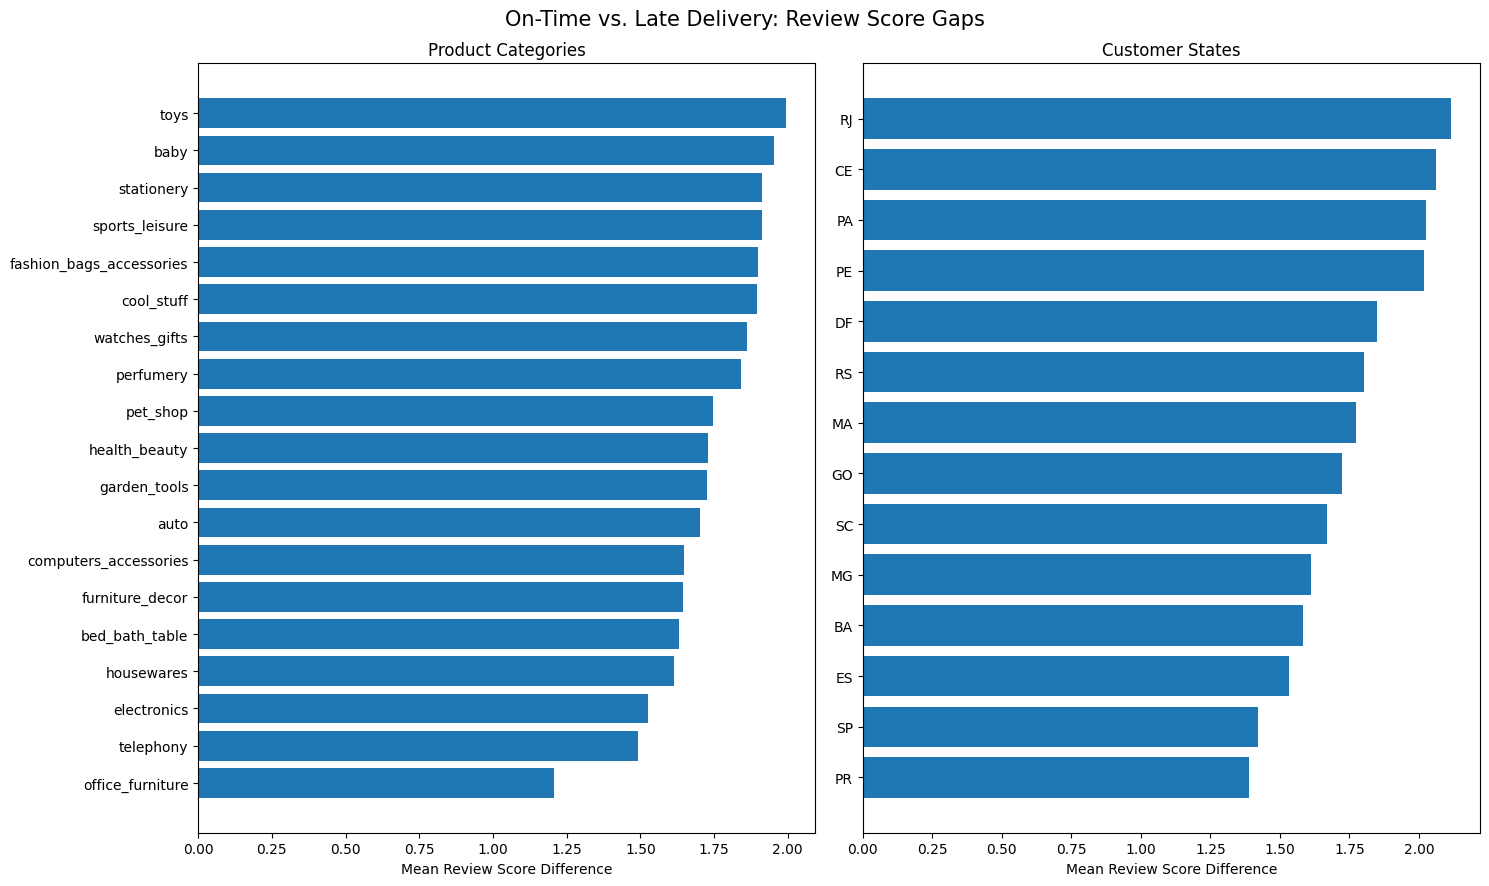

Figure saved to: /content/CS690_Capstone/06_outputs/figures/delivery_review_gap_by_category_state.png


In [ ]:
import matplotlib.pyplot as plt

def calculate_delivery_gaps(group_col):
    grouped = (
        customer_experience
        .dropna(subset=[
            group_col,
            "review_score",
            "late_delivery_flag"
        ])
        .groupby([group_col, "late_delivery_flag"])
        ["review_score"]
        .agg(["count", "mean"])
    )

    counts = grouped["count"].unstack()
    means = grouped["mean"].unstack()

    results = pd.DataFrame({
        "on_time_count": counts[0],
        "late_count": counts[1],
        "on_time_review": means[0],
        "late_review": means[1]
    }).dropna()

    results = results[
        (results["on_time_count"] >= 500)
        & (results["late_count"] >= 100)
    ].copy()

    results["review_gap"] = (
        results["on_time_review"]
        - results["late_review"]
    )

    return results.sort_values("review_gap")


category_gaps = calculate_delivery_gaps("primary_category")
state_gaps = calculate_delivery_gaps("customer_state")

print("Qualifying categories:", len(category_gaps))
print("Qualifying states:", len(state_gaps))

fig, axes = plt.subplots(1, 2, figsize=(15, 9))

axes[0].barh(
    category_gaps.index,
    category_gaps["review_gap"]
)
axes[0].set_title("Product Categories")
axes[0].set_xlabel("Mean Review Score Difference")

axes[1].barh(
    state_gaps.index,
    state_gaps["review_gap"]
)
axes[1].set_title("Customer States")
axes[1].set_xlabel("Mean Review Score Difference")

fig.suptitle(
    "On-Time vs. Late Delivery: Review Score Gaps",
    fontsize=15
)

plt.tight_layout()

output_path = (
    REPO_DIR / "06_outputs" / "figures"
    / "delivery_review_gap_by_category_state.png"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", output_path)

On-time deliveries received higher average review scores across all 19 qualifying product categories and 14 customer states, although the size of the difference varied. Toys and baby products showed some of the largest category-level gaps, while office furniture showed the smallest. Geographically, Rio de Janeiro (RJ) had the largest gap and Paraná (PR) the smallest. These findings suggest that the relationship between delivery timeliness and customer satisfaction is widespread, but its magnitude differs across products and regions.

## Improved Customer Experience: Model Selection

The baseline analysis found that late deliveries were associated with lower customer review scores across product categories and customer states.

The improved analysis will use binary logistic regression to examine whether delivery delay is associated with low customer reviews (review scores of 2 or below), while accounting for product category, customer geography, and freight costs.

The main results will include odds ratios, 95% confidence intervals, and predicted probabilities of low reviews at different delivery delays.

This approach provides more detailed evidence than the baseline comparisons, although the results will remain observational rather than causal.

Check whether the data supports this approach

In [ ]:
# Check review distribution for proposed logistic regression

model_candidate = customer_experience.dropna(
    subset=["review_score", "delivery_delay_days"]
).copy()

review_distribution = (
    model_candidate["review_score"]
    .value_counts()
    .sort_index()
)

low_review_count = (
    model_candidate["review_score"] <= 2
).sum()

low_review_percent = (
    low_review_count / len(model_candidate) * 100
)

print("Orders with valid reviews and delivery delays:",
      len(model_candidate))

print("Low-review orders:", low_review_count)

print("Low-review percentage:",
      round(low_review_percent, 2), "%")

print("Non-integer review scores:",
      (model_candidate["review_score"] % 1 != 0).sum())

print("\nReview score distribution:")
display(review_distribution)

print("\nAvailable candidate control columns:")
print([
    col for col in customer_experience.columns
    if any(term in col.lower()
           for term in ["freight", "category", "state"])
])

Orders with valid reviews and delivery delays: 95830
Low-review orders: 12240
Low-review percentage: 12.77 %
Non-integer review scores: 116

Review score distribution:


,count
review_score,
1.000000,9316
1.500000,8
2.000000,2916
2.500000,30
3.000000,7916
3.333333,1
3.500000,23
4.000000,18868
4.333333,1



Available candidate control columns:
['freight_total', 'freight_percentage', 'category_count', 'primary_category', 'seller_category_count', 'seller_avg_freight', 'seller_state', 'customer_state']


Of the 95,830 orders with valid review scores and delivery-delay information, 12,240 (12.77%) received a low review score of 2 or below. Only 116 orders had fractional review scores resulting from aggregation. These findings support using binary logistic regression to examine the association between delivery delay and low customer ratings while accounting for product category, customer geography, and freight costs.

# Feature refinement

### Seller Performance Features

In [ ]:
# Prepare refined seller features

seller_refined = seller_metrics.copy()

# Revenue per seller order
seller_refined["seller_sales_per_order"] = (
    seller_refined["seller_total_sales"]
    / seller_refined["seller_order_count"].replace(0, np.nan)
)

# Seller scale: reduce the skew of order counts
seller_refined["seller_log_order_count"] = np.log1p(
    seller_refined["seller_order_count"]
)

# Eligibility flags for different analyses
seller_refined["sales_eligible"] = (
    seller_refined["seller_order_count"] >= 10
)

seller_refined["review_eligible"] = (
    seller_refined["seller_reviewed_order_count"] >= 10
)

seller_refined["delivery_eligible"] = (
    seller_refined["seller_delivery_order_count"] >= 10
)

seller_refined["quality_eligible"] = (
    seller_refined["review_eligible"]
    & seller_refined["delivery_eligible"]
)

print("Total sellers:", len(seller_refined))
print("Sales analysis eligible:",
      seller_refined["sales_eligible"].sum())
print("Review analysis eligible:",
      seller_refined["review_eligible"].sum())
print("Delivery analysis eligible:",
      seller_refined["delivery_eligible"].sum())
print("Review + delivery eligible:",
      seller_refined["quality_eligible"].sum())

Total sellers: 3095
Sales analysis eligible: 1271
Review analysis eligible: 1244
Delivery analysis eligible: 1217
Review + delivery eligible: 1215


### Customer Experience Features

In [ ]:
# Inspect candidate customer model features

customer_features = customer_experience[
    [
        "order_id",
        "review_score",
        "delivery_delay_days",
        "freight_percentage",
        "order_value",
        "primary_category",
        "customer_state"
    ]
].copy()

# Treat infinite values as missing
customer_features = customer_features.replace(
    [np.inf, -np.inf], np.nan
)

print("Total orders:", len(customer_features))

print("\nMissing values:")
display(
    customer_features.isna()
    .sum()
    .to_frame("Missing Count")
)

print("\nNumerical feature distributions:")
display(
    customer_features[
        [
            "delivery_delay_days",
            "freight_percentage",
            "order_value"
        ]
    ].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
    ).round(2)
)

print("\nProduct category counts:")
print("Unique categories:",
      customer_features["primary_category"].nunique())

display(
    customer_features["primary_category"]
    .value_counts()
    .head(15)
)

print("\nCustomer state counts:")
print("Unique states:",
      customer_features["customer_state"].nunique())

display(
    customer_features["customer_state"]
    .value_counts()
    .head(15)
)

Total orders: 99441

Missing values:


,Missing Count
order_id,0
review_score,768
delivery_delay_days,2965
freight_percentage,775
order_value,775
primary_category,2164
customer_state,0



Numerical feature distributions:


,delivery_delay_days,freight_percentage,order_value
count,96476.00,98666.00,98666.00
mean,-11.18,30.84,137.75
std,10.19,31.48,210.65
min,-146.02,0.00,0.85
1%,-35.15,2.49,11.98
25%,-16.24,13.19,45.90
50%,-11.95,22.44,86.90
75%,-6.39,38.02,149.90
99%,18.94,146.19,998.90
max,188.98,2144.71,13440.00



Product category counts:
Unique categories: 73


,count
primary_category,
bed_bath_table,9385
health_beauty,8810
sports_leisure,7668
computers_accessories,6679
furniture_decor,6350
housewares,5812
watches_gifts,5584
telephony,4177
auto,3891



Customer state counts:
Unique states: 27


,count
customer_state,
SP,41746
RJ,12852
MG,11635
RS,5466
PR,5045
SC,3637
BA,3380
DF,2140
ES,2033


In [ ]:
# Prepare seller samples for improved analysis

seller_sales_model = seller_refined.loc[
    seller_refined["sales_eligible"],
    [
        "seller_sales_per_order",
        "seller_product_count",
        "seller_category_count",
        "seller_log_order_count"
    ]
].replace([np.inf, -np.inf], np.nan).dropna().copy()

seller_quality_model = seller_refined.loc[
    seller_refined["quality_eligible"],
    [
        "seller_average_review",
        "seller_late_delivery_rate",
        "seller_product_count",
        "seller_category_count",
        "seller_log_order_count"
    ]
].replace([np.inf, -np.inf], np.nan).dropna().copy()

print("Seller sales sample:", len(seller_sales_model))
print("Seller quality sample:", len(seller_quality_model))

display(seller_sales_model.head())
display(seller_quality_model.head())

Seller sales sample: 1271
Seller quality sample: 1215


,seller_sales_per_order,seller_product_count,seller_category_count,seller_log_order_count
1,125.400150,11,2,5.303305
3,24.205882,24,1,3.951244
5,124.763987,88,1,5.068904
6,77.500000,9,1,2.639057
9,150.074074,23,2,4.912655


,seller_average_review,seller_late_delivery_rate,seller_product_count,seller_category_count,seller_log_order_count
1,4.000000,0.067010,11,2,5.303305
3,3.938776,0.187500,24,1,3.951244
5,4.142857,0.083871,88,1,5.068904
6,3.666667,0.166667,9,1,2.639057
9,4.333333,0.092308,23,2,4.912655


### Customer Experience: Refined Modeling Features

In [ ]:
# Prepare customer data for logistic regression

customer_model = customer_features.copy()

# Keep orders with valid numeric modeling information
customer_model = customer_model.dropna(
    subset=[
        "review_score",
        "delivery_delay_days",
        "freight_percentage"
    ]
).copy()

# Binary outcome: 1 = low review, 0 = other review
customer_model["low_review"] = (
    customer_model["review_score"] <= 2
).astype(int)

# Reduce freight-percentage skew without removing extremes
customer_model["log_freight_percentage"] = np.log1p(
    customer_model["freight_percentage"]
)

# Preserve missing product categories as a separate group
customer_model["primary_category"] = (
    customer_model["primary_category"].fillna("Unknown")
)

# Group categories with fewer than 500 modeling observations
category_counts = customer_model["primary_category"].value_counts()

common_categories = category_counts[
    category_counts >= 500
].index

customer_model["category_group"] = np.where(
    customer_model["primary_category"].isin(common_categories),
    customer_model["primary_category"],
    "Other"
)

# Group states with fewer than 500 modeling observations
state_counts = customer_model["customer_state"].value_counts()

common_states = state_counts[
    state_counts >= 500
].index

customer_model["state_group"] = np.where(
    customer_model["customer_state"].isin(common_states),
    customer_model["customer_state"],
    "Other"
)

# Review the refined dataset
print("Orders prepared:", len(customer_model))
print("Low-review orders:", customer_model["low_review"].sum())
print("Low-review rate:",
      round(customer_model["low_review"].mean() * 100, 2), "%")

print("Category groups:",
      customer_model["category_group"].nunique())
print("State groups:",
      customer_model["state_group"].nunique())

print("Unique order IDs:",
      customer_model["order_id"].nunique())

display(
    customer_model[
        [
            "low_review",
            "delivery_delay_days",
            "log_freight_percentage",
            "category_group",
            "state_group"
        ]
    ].head()
)

Orders prepared: 95830
Low-review orders: 12240
Low-review rate: 12.77 %
Category groups: 27
State groups: 18
Unique order IDs: 95830


,low_review,delivery_delay_days,log_freight_percentage,category_group,state_group
0,0,-7.107488,3.403739,housewares,SP
1,0,-5.355729,3.004414,perfumery,BA
2,0,-17.245498,2.566488,auto,GO
3,0,-12.980069,4.118133,pet_shop,Other
4,0,-9.238171,3.802634,stationery,SP


### Feature Refinement Findings

Seller data was separated into 1,271 sellers eligible for sales analysis and 1,215 eligible for review and delivery-quality analysis. Sales per order and log-transformed order counts were retained to examine seller performance beyond total sales.

The customer modeling dataset contains 95,830 unique orders, including 12,240 low-review orders (12.77%). Product categories were consolidated into 27 groups and customer states into 18 groups. Delivery delays were preserved, while freight percentage was log-transformed to reduce skewness.

These refined datasets are ready for improved statistical modeling.

# Improved Statistical Methods

### Seller Performance: Multivariable Regression

In [ ]:
import statsmodels.api as sm

# Prepare data for seller-quality regression
seller_quality_reg = seller_quality_model.copy()

seller_quality_reg["seller_reviewed_order_count"] = (
    seller_refined.loc[
        seller_quality_reg.index,
        "seller_reviewed_order_count"
    ]
)

# Transform product count to reduce skewness
seller_quality_reg["log_product_count"] = np.log1p(
    seller_quality_reg["seller_product_count"]
)

# Define predictors
seller_predictors = [
    "seller_late_delivery_rate",
    "log_product_count",
    "seller_category_count",
    "seller_log_order_count"
]

X_seller = sm.add_constant(
    seller_quality_reg[seller_predictors]
)

y_seller = seller_quality_reg["seller_average_review"]

# Weight by number of reviewed orders
weights = seller_quality_reg["seller_reviewed_order_count"]

# Fit weighted regression with robust standard errors
seller_quality_fit = sm.WLS(
    y_seller,
    X_seller,
    weights=weights
).fit(cov_type="HC3")

# Display model results
seller_coefficients = pd.DataFrame({
    "Coefficient": seller_quality_fit.params,
    "p-value": seller_quality_fit.pvalues,
    "CI Lower": seller_quality_fit.conf_int()[0],
    "CI Upper": seller_quality_fit.conf_int()[1]
})

print("Sellers analyzed:", int(seller_quality_fit.nobs))
print("R-squared:", round(seller_quality_fit.rsquared, 3))

display(seller_coefficients.round(4))

# Effect of a 10-percentage-point increase in late deliveries
late_rate_effect = (
    seller_quality_fit.params["seller_late_delivery_rate"] * 0.10
)

print(
    "Estimated review-score difference for a "
    "10-percentage-point increase in late-delivery rate:",
    round(late_rate_effect, 3)
)

Sellers analyzed: 1215
R-squared: 0.25


,Coefficient,p-value,CI Lower,CI Upper
const,4.4750,0.0000,4.3767,4.5733
seller_late_delivery_rate,-2.7278,0.0000,-3.1579,-2.2977
log_product_count,-0.0246,0.1179,-0.0553,0.0062
seller_category_count,-0.0030,0.3545,-0.0093,0.0033
seller_log_order_count,-0.0034,0.7892,-0.0279,0.0212


Estimated review-score difference for a 10-percentage-point increase in late-delivery rate: -0.273


Among 1,215 eligible sellers, weighted regression showed that a 10-percentage-point increase in late-delivery rate was associated with a 0.273-point decrease in average review score (95% CI: -0.316 to -0.230), after accounting for seller order volume and product variety. The model explained 25% of the weighted variation in seller review scores, while the other predictors were not statistically significant.

### Customer Experience: Binary Logistic Regression

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Logistic regression:
# 1 = low review (2 stars or below)
# 0 = review above 2 stars

customer_formula = (
    "low_review ~ delivery_delay_days"
    " + log_freight_percentage"
    " + C(category_group)"
    " + C(state_group)"
)

customer_logit_fit = smf.glm(
    formula=customer_formula,
    data=customer_model,
    family=sm.families.Binomial()
).fit(cov_type="HC3", maxiter=100)

# Main predictor results
delay_coefficient = customer_logit_fit.params["delivery_delay_days"]
delay_p_value = customer_logit_fit.pvalues["delivery_delay_days"]

delay_ci = customer_logit_fit.conf_int().loc[
    "delivery_delay_days"
]

# Convert log-odds coefficients to odds ratios
delay_odds_ratio = np.exp(delay_coefficient)
delay_or_ci = np.exp(delay_ci)

print("Model converged:", customer_logit_fit.converged)
print("Orders analyzed:", int(customer_logit_fit.nobs))

print("\nDelivery delay results:")
print("Coefficient:", round(delay_coefficient, 4))
print("Odds ratio per additional day:", round(delay_odds_ratio, 4))
print("95% CI:", tuple(delay_or_ci.round(4)))
print("p-value:", delay_p_value)

Model converged: True
Orders analyzed: 95830

Delivery delay results:
Coefficient: 0.0738
Odds ratio per additional day: 1.0766
95% CI: (1.0733, 1.08)
p-value: 0.0


Calculate predicted low-review probabilities

In [ ]:
# Predicted probability of a low review at selected delays

delay_scenarios = [-15, -7, 0, 7, 15]

prediction_results = []

for delay in delay_scenarios:

    # Retain each order's original category, state, and freight
    scenario_data = customer_model.copy()

    # Change only delivery delay
    scenario_data["delivery_delay_days"] = delay

    # Predict and average across all orders
    predicted_probabilities = customer_logit_fit.predict(
        scenario_data
    )

    prediction_results.append({
        "Delivery Delay (Days)": delay,
        "Predicted Low-Review Probability (%)":
            predicted_probabilities.mean() * 100
    })

customer_delay_predictions = pd.DataFrame(
    prediction_results
)

display(customer_delay_predictions.round(2))

,Delivery Delay (Days),Predicted Low-Review Probability (%)
0,-15,8.68
1,-7,14.58
2,0,22.15
3,7,32.12
4,15,45.79


### Seller Performance: Sales per Order Regression

In [ ]:
# Prepare seller sales-per-order regression

seller_sales_reg = seller_sales_model.loc[
    seller_sales_model["seller_sales_per_order"] > 0
].copy()

# Log transformations for skewed variables
seller_sales_reg["log_sales_per_order"] = np.log(
    seller_sales_reg["seller_sales_per_order"]
)

seller_sales_reg["log_product_count"] = np.log1p(
    seller_sales_reg["seller_product_count"]
)

# Predictor variables
sales_predictors = [
    "log_product_count",
    "seller_category_count",
    "seller_log_order_count"
]

X_sales = sm.add_constant(
    seller_sales_reg[sales_predictors]
)

y_sales = seller_sales_reg["log_sales_per_order"]

# Fit regression with robust standard errors
seller_sales_fit = sm.OLS(
    y_sales,
    X_sales
).fit(cov_type="HC3")

# Results
seller_sales_coefficients = pd.DataFrame({
    "Coefficient": seller_sales_fit.params,
    "p-value": seller_sales_fit.pvalues,
    "CI Lower": seller_sales_fit.conf_int()[0],
    "CI Upper": seller_sales_fit.conf_int()[1]
})

print("Sellers analyzed:", int(seller_sales_fit.nobs))
print("R-squared:", round(seller_sales_fit.rsquared, 3))

display(seller_sales_coefficients.round(4))

Sellers analyzed: 1271
R-squared: 0.011


,Coefficient,p-value,CI Lower,CI Upper
const,5.0161,0.0000,4.8544,5.1778
log_product_count,-0.0078,0.8377,-0.0830,0.0673
seller_category_count,-0.0089,0.2486,-0.0240,0.0062
seller_log_order_count,-0.0639,0.0507,-0.1281,0.0002


The seller sales-per-order regression explained only 1.1% of variation in log sales per order among 1,271 eligible sellers. Product count, category count, and seller order volume were not statistically significant predictors at the 0.05 level. These findings suggest that the selected seller characteristics provide limited explanatory value for sales per order, whereas the separate seller-quality analysis identified a clearer relationship between delivery reliability and customer reviews.

# Baseline vs. Improved Comparison

In [ ]:
comparison = pd.DataFrame({
    "Analysis": [
        "Seller sales",
        "Seller quality",
        "Customer experience"
    ],

    "Notebook 09 Baseline": [
        "Total sales vs order count: rho = 0.853 "
        "(all sellers), 0.753 (10+ orders)",

        "No separate seller-quality model",

        "Review gap = 1.72 points; "
        "rank-biserial = 0.554; "
        "delay Spearman rho = -0.176"
    ],

    "Notebook 10 Improved": [
        f"Sales-per-order regression: "
        f"R² = {seller_sales_fit.rsquared:.3f}",

        f"Weighted seller-review regression: "
        f"R² = {seller_quality_fit.rsquared:.3f}; "
        f"late-rate effect per +10 pp = "
        f"{seller_quality_fit.params['seller_late_delivery_rate'] * 0.10:.3f}",

        f"Low-review logistic regression: "
        f"OR per delay day = {delay_odds_ratio:.4f}"
    ]
})

display(comparison)

,Analysis,Notebook 09 Baseline,Notebook 10 Improved
0,Seller sales,Total sales vs order count: rho = 0.853 (all s...,Sales-per-order regression: R² = 0.011
1,Seller quality,No separate seller-quality model,Weighted seller-review regression: R² = 0.250;...
2,Customer experience,Review gap = 1.72 points; rank-biserial = 0.55...,Low-review logistic regression: OR per delay d...


The improved analyses provided more detailed findings than the original baseline. Seller sales-per-order regression had limited explanatory power (R² = 0.011), while the new seller-quality regression identified a substantial negative association between late-delivery rate and average review score (R² = 0.250).

For customer experience, logistic regression extended the baseline findings by estimating that each additional day of delivery delay was associated with 7.66% higher odds of a low review after adjusting for category, state, and freight costs.

Delivery reliability emerged as the strongest consistent finding across the seller and customer analyses. However, the results remain observational, and model assumptions, predictive performance, and robustness require further validation.

Preliminary Improved Results

In [ ]:
preliminary_results = pd.DataFrame({
    "Analysis": [
        "Seller sales per order",
        "Seller quality",
        "Customer experience"
    ],
    "Observations": [
        int(seller_sales_fit.nobs),
        int(seller_quality_fit.nobs),
        int(customer_logit_fit.nobs)
    ],
    "Key result": [
        f"R² = {seller_sales_fit.rsquared:.3f}",
        (
            f"Review change per +10 pp late rate = "
            f"{seller_quality_fit.params['seller_late_delivery_rate'] * 0.10:.3f}; "
            f"R² = {seller_quality_fit.rsquared:.3f}"
        ),
        (
            f"Odds ratio per additional delay day = "
            f"{np.exp(customer_logit_fit.params['delivery_delay_days']):.4f}"
        )
    ]
})

display(preliminary_results)

,Analysis,Observations,Key result
0,Seller sales per order,1271,R² = 0.011
1,Seller quality,1215,Review change per +10 pp late rate = -0.273; R...
2,Customer experience,95830,Odds ratio per additional delay day = 1.0766


# Final Notes



- **Seller Performance:** Following instructor feedback, the analysis shifted from total sales toward sales per order, average review scores, and delivery reliability. Most sales-per-order relationships were very weak, while seller late-delivery rate and average review score showed a moderate negative correlation (ρ = -0.404).

- **Seller Regression Results:** Among 1,215 sellers, weighted regression showed that a 10-percentage-point increase in late-delivery rate was associated with a 0.273-point decrease in average review score (R² = 0.250). Seller size and product variety were not statistically significant predictors. The separate sales-per-order regression had limited explanatory power (R² = 0.011).

- **Customer Experience:** Binary logistic regression analyzed 95,830 orders, including 12,240 low reviews (12.77%). Each additional day of delivery delay was associated with 7.66% higher odds of a low review (OR = 1.0766; 95% CI: 1.0733–1.0800), after controlling for product category, customer state, and freight percentage.

- **Predicted Probabilities:** The estimated probability of a low review increased from 8.68% for deliveries 15 days early to 22.15% for deliveries on the estimated date and 45.79% for deliveries 15 days late.

- **Category and State Analysis:** On-time deliveries received higher average reviews across all 19 qualifying product categories and 14 customer states. The review gaps varied across groups, suggesting differences in the strength of the delivery-satisfaction relationship.

- **Baseline Comparison:** The improved analyses extended Notebook 09 by introducing multivariable methods and additional seller-quality measures. Delivery reliability emerged as the clearest consistent finding, while the selected seller characteristics explained little variation in sales per order.

## Limitations and Next Steps

- The findings represent associations, not causal relationships.
- The customer logistic model assumes a linear relationship between delivery delay and the log-odds of a low review.
- Seller sales per order includes order count in its calculation, requiring cautious interpretation.
- **November 2–6:** Validate model assumptions and predictive performance, examine sensitivity to extreme values and grouped categories, assess fractional review scores, and check seller eligibility thresholds and regression weighting.